In [1]:
import openmc
from openmc.deplete import d1s
from openmc_model import openmc_model
import numpy as np
import matplotlib.pyplot as plt

In [2]:
d1s_sp = openmc.StatePoint('d1s_results/statepoint.100.h5')

In [3]:
# retrieve mesh
gflux_rm = d1s_sp.get_tally(name='flux_rm')

In [ ]:
# only for d1s
openmc.config['chain_file'] = '/home/segantin/openmc_models/CROSS_SECTIONS/chain_endfb80_sfr.xml'

model = openmc_model()

nuclides = d1s.prepare_tallies(model)
# [s] from 0.1 to ~115 days
# timesteps = np.diff(np.logspace(0.1, 7, num=100))
timesteps = np.diff(np.logspace(0.1, 7, num=10))
timesteps = np.insert(timesteps, 0, 10)  # [s] add 10s of shot time
source_rates = np.zeros(len(timesteps))
# n/s  # [n/s] initial source rate // Full power H-mode DD pulse is 7E18 n/s
source_rates[0] = 1e9  # [n/s]
factors = d1s.time_correction_factors(
    nuclides, timesteps, list(source_rates))
gflux_rm = d1s.apply_time_correction(gflux_rm, factors, 2)

In [5]:
counter = 0
for i in gflux_rm.mean.squeeze():
    if i not in [0.0, np.nan]:
        counter += 1
print(f"Number of non-zero fluxes: {counter}")

Number of non-zero fluxes: 125000


In [6]:
meshgrid = gflux_rm.find_filter(openmc.MeshFilter).mesh
x, y, z = np.moveaxis(meshgrid.centroids, -1, 0)
mesh_gflux_mean = gflux_rm.get_reshaped_data(expand_dims=True).squeeze()
mesh_gflux_relerr = gflux_rm.get_reshaped_data(value='rel_err', expand_dims=True).squeeze()

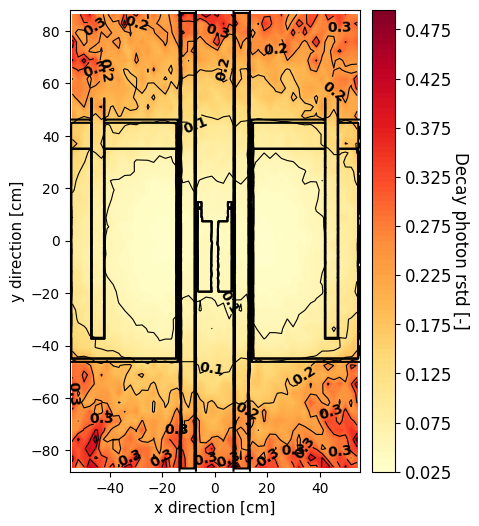

In [8]:
# xy
fig, ax = plt.subplots(figsize=(8, 6))

p3 = ax.contourf(x[:, :, 25].T, y[:, :, 25].T, mesh_gflux_relerr[:, :, 25].T, levels=100, cmap='YlOrRd')
p4 = ax.contour(x[:, :, 25].T, y[:, :, 25].T, mesh_gflux_relerr[:, :, 25].T, colors='k', linewidths=.8)
contour_labels = ax.clabel(p4, colors='k', fmt=r'$\mathbf{%1.1f}$', fontsize=10)
im_ratio = len(x[:, :, 25]) / len(y[:, :, 25])
cbar2 = fig.colorbar(p3, ax=ax, pad=0.02)
cbar2.ax.tick_params(labelsize=12)
cbar2.set_label('Decay photon rstd [-]', rotation=270, fontsize=12, labelpad=12)
ax.set_xlabel('x direction [cm]', fontsize=11)
ax.set_ylabel('y direction [cm]', fontsize=11)
ax.set_aspect(1)

ax = model.plot(
    outline='only',
    extent=model.bounding_box.extent['xy'],
    axes=ax,  # Use the same axis as ax1\n",
    pixels=10_000_000,  #avoids rounded corners on outline
    color_by='material',
)